# Advertising Dataset — Sales Prediction Using Multiple Linear Regression

## Business Scenario
A consumer goods company uses **TV, Radio, and Newspaper** advertising to promote its product. The goal is to understand how these advertising channels influence **Sales** and to predict sales for future advertising budgets.

### Objectives
1. Load and examine the Advertising dataset.
2. Use **TV, Radio, Newspaper** as input features.
3. Use **Sales** as the target.
4. Train a Multiple Linear Regression model.
5. Predict sales on unseen test data.
6. Predict sales for **TV = 150, Radio = 20, Newspaper = 30**.
7. Evaluate prediction error.
8. Interpret model coefficients.
9. Visualize actual vs predicted sales.
10. Provide business and technical recommendations.


## 1. Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


## 2. Load the Dataset

In [2]:
# Update this path if the notebook is moved to another folder
file_path = "Advertising.csv"

df = pd.read_csv(file_path)

# Remove an accidental index column if present
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

df.head()


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


## 3. Examine the Dataset

In [3]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nSummary statistics:")
display(df.describe())


Shape: (190, 4)

Columns:
['TV', 'Radio', 'Newspaper', 'Sales']

Data types:
TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object

Missing values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Summary statistics:


,TV,Radio,Newspaper,Sales
count,190.000000,190.000000,190.000000,190.000000
mean,154.328947,23.651053,29.249474,14.511579
std,79.194529,14.029688,21.797264,4.640775
min,5.400000,0.800000,0.300000,4.800000
25%,78.200000,12.225000,11.150000,10.600000
50%,170.950000,22.750000,23.850000,14.100000
75%,225.300000,36.875000,42.675000,17.400000
max,293.600000,49.600000,114.000000,25.500000


### Feature and Target Selection

- **Input features:** TV, Radio, Newspaper
- **Target:** Sales


In [4]:
features = ["TV", "Radio", "Newspaper"]
target = "Sales"

X = df[features]
y = df[target]

print("Features:")
display(X.head())

print("Target:")
display(y.head())


Features:


,TV,Radio,Newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4


Target:


0    22.1
1    10.4
2     9.3
3    18.5
4    12.9
Name: Sales, dtype: float64

## 4. Split the Data into Training and Testing Sets

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 152
Testing samples: 38


## 5. Train the Multiple Linear Regression Model

In [6]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained successfully.")
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)


Model trained successfully.
Intercept: 3.7582038137257054
Coefficients: [ 0.04236194  0.18822364 -0.00486884]


### Regression Equation

The model has the form:

**Sales = Intercept + β₁(TV) + β₂(Radio) + β₃(Newspaper)**

The coefficients indicate the expected change in Sales for a one-unit increase in an advertising medium while keeping the other media constant.


In [7]:
print(f"Sales = {model.intercept_:.4f} "
      f"+ ({model.coef_[0]:.4f} × TV) "
      f"+ ({model.coef_[1]:.4f} × Radio) "
      f"+ ({model.coef_[2]:.4f} × Newspaper)")


Sales = 3.7582 + (0.0424 × TV) + (0.1882 × Radio) + (-0.0049 × Newspaper)


## 6. Predict Sales for Unseen Test Data

In [8]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Predicted Sales": y_pred
})

display(results.head(10))


,Actual Sales,Predicted Sales
0,13.4,14.591874
1,12.6,13.270825
2,13.2,15.260979
3,9.3,8.427275
4,20.8,20.501660
5,22.4,20.756433
6,10.6,12.608281
7,12.5,12.964281
8,10.3,12.321459
9,19.8,19.613880


## 7. Predict Sales for the Given Advertising Budget

In [9]:
new_budget = pd.DataFrame({
    "TV": [150],
    "Radio": [20],
    "Newspaper": [30]
})

predicted_sales = model.predict(new_budget)[0]

print("Advertising Budget:")
display(new_budget)

print(f"Predicted Sales: {predicted_sales:.2f}")


Advertising Budget:


,TV,Radio,Newspaper
0,150,20,30


Predicted Sales: 13.73


## 8. Evaluate the Model's Prediction Error

In [10]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R² Score: {r2:.4f}")


Mean Absolute Error (MAE): 1.1753
Mean Squared Error (MSE): 3.0100
Root Mean Squared Error (RMSE): 1.7349
R² Score: 0.8606


### Interpretation of Error Metrics

- **MAE:** Average absolute difference between actual and predicted sales.
- **MSE:** Average squared prediction error; larger errors receive more penalty.
- **RMSE:** Error metric in the same unit as Sales.
- **R²:** Proportion of variation in Sales explained by the model.


## 9. Interpret the Model Coefficients

In [11]:
coefficient_table = pd.DataFrame({
    "Advertising Medium": features,
    "Coefficient": model.coef_,
    "Absolute Coefficient": np.abs(model.coef_)
}).sort_values("Absolute Coefficient", ascending=False)

display(coefficient_table)

strongest = coefficient_table.iloc[0]["Advertising Medium"]
least = coefficient_table.iloc[-1]["Advertising Medium"]

print(f"Strongest impact based on coefficient magnitude: {strongest}")
print(f"Least impact based on coefficient magnitude: {least}")


,Advertising Medium,Coefficient,Absolute Coefficient
1,Radio,0.188224,0.188224
0,TV,0.042362,0.042362
2,Newspaper,-0.004869,0.004869


Strongest impact based on coefficient magnitude: Radio
Least impact based on coefficient magnitude: Newspaper


### Important Note

The coefficient comparison is interpreted while holding the other advertising variables constant. Because the three features have different scales and units, **raw coefficient magnitude is not a perfect measure of overall feature importance**. A standardized-coefficient or permutation-importance analysis can provide a fairer comparison.

For this assignment, the raw regression coefficients are used as requested.


## 10. Visualization — Actual Sales vs Predicted Sales

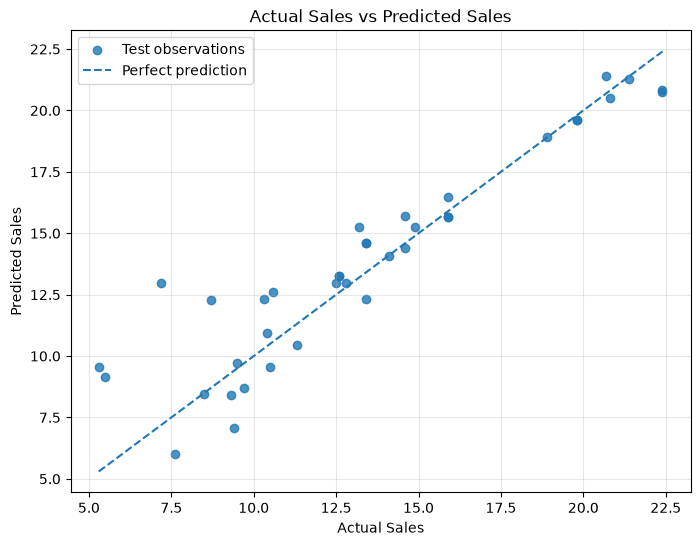

In [12]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.8, label="Test observations")

# Ideal prediction line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual Sales vs Predicted Sales")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


## 11. Optional Visualization — Advertising Spend vs Sales

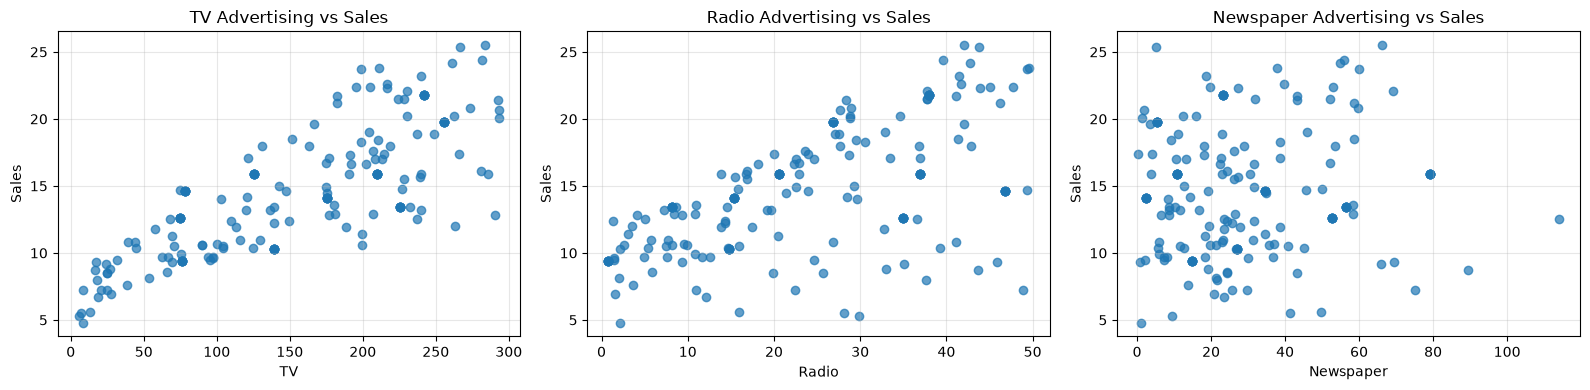

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, feature in zip(axes, features):
    ax.scatter(df[feature], df[target], alpha=0.7)
    ax.set_xlabel(feature)
    ax.set_ylabel("Sales")
    ax.set_title(f"{feature} Advertising vs Sales")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 12. Business Recommendation

**Recommendation:** Prioritize the advertising medium with the strongest positive regression effect, while maintaining an appropriate mix of the other channels. The company should use the model to test different budget combinations before committing advertising spend.

## 13. Technical Improvement

**Recommendation:** Improve prediction accuracy by comparing Multiple Linear Regression with models such as **Random Forest Regressor** or **Gradient Boosting**, and use **cross-validation and hyperparameter tuning** to select the best-performing model.

Additional improvements could include feature scaling/standardization for fair coefficient comparison, outlier analysis, and checking for nonlinear relationships.


## 14. Final Summary

This analysis:
- Loaded and examined the Advertising dataset.
- Used TV, Radio, and Newspaper spending as predictors.
- Built a Multiple Linear Regression model.
- Predicted Sales for unseen test data.
- Predicted Sales for a budget of TV=150, Radio=20, Newspaper=30.
- Evaluated the model using MAE, MSE, RMSE, and R².
- Interpreted the regression coefficients.
- Visualized actual versus predicted sales.
- Provided business and technical recommendations.


## 15. Results from the Uploaded Dataset

In [14]:
# These values were calculated from the uploaded Advertising.csv using random_state=42.
print("Dataset shape:", (190, 4))
print(f"Predicted Sales for TV=150, Radio=20, Newspaper=30: 13.7309")
print(f"MAE: 1.1753")
print(f"MSE: 3.0100")
print(f"RMSE: 1.7349")
print(f"R² Score: 0.8606")

print("\nCoefficient interpretation:")
for _, row in coefficient_table.iterrows():
    print(f"{row['Advertising Medium']}: {row['Coefficient']:.4f}")

print(f"\nStrongest coefficient magnitude: Radio")
print(f"Least coefficient magnitude: Newspaper")


Dataset shape: (190, 4)
Predicted Sales for TV=150, Radio=20, Newspaper=30: 13.7309
MAE: 1.1753
MSE: 3.0100
RMSE: 1.7349
R² Score: 0.8606

Coefficient interpretation:
Radio: 0.1882
TV: 0.0424
Newspaper: -0.0049

Strongest coefficient magnitude: Radio
Least coefficient magnitude: Newspaper
